In [1]:
import numpy as np
import sys
import os

sys.path.append(os.path.abspath(".."))

from class_particle_filter import AuxiliaryParticleFilter
from simulations import system_simulation
from plot import plot_results

# EJEMPLO LINEAL GAUSSIANO

Estado:

$$
x_t = A x_{t-1} + w_t, \;\;\; w_t \sim N(0,Q)
$$

Observación:
$$
y_t = H x_t + v_t, \;\;\; v_t \sim N(0,R)
$$

### Ejemplo 1D

$$
A = [1.0] \;\;\; H=[1.0] \;\;\; Q=[0.1] \;\;\; R = [0.5]
$$


In [2]:
# Modelo lineal 1D

A = np.array([[1.0]])
H = np.array([[1.0]])   # observación directa

Q = 0.1  # ruido proceso
R = 0.5  # ruido observación

def f(x):
    return A @ x

def h(x):
    return H @ x

In [3]:
#Simulacion
T = 50
x0 = np.array([0.0])

x_true, y_obs = system_simulation(A, H, Q, R, x0, T)

In [4]:
pf = AuxiliaryParticleFilter(
    N=1000,
    state_transition=f,
    measurement_function=h,
    Q=Q,
    R=R
)

pf.initialize(mean=np.array([0.0]), cov=np.array([[1.0]]))

In [5]:
x_est = pf.run_filter(y_obs, resample_threshold=500)

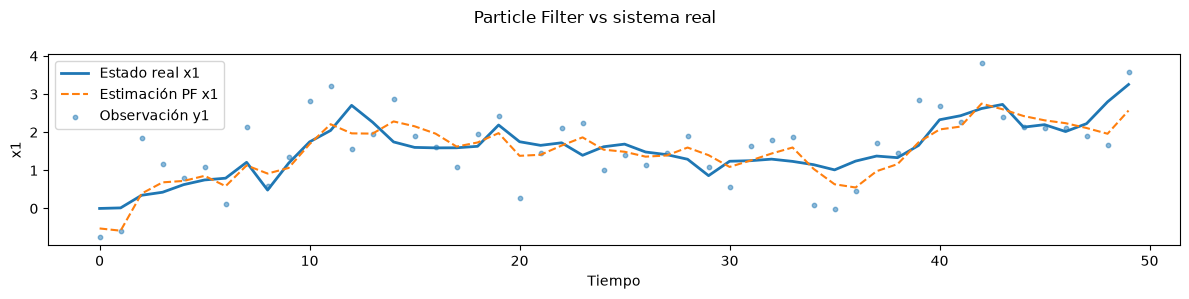

In [6]:
# --- Plot ---
plot_results(x_true, y_obs, x_est)

### EJEMPLO 2D -> OBSERVACION 1D

$$
A = \begin{bmatrix}
1 &1 \\
0 &1
\end{bmatrix}
\;\;
H = \begin{bmatrix}
1 &0 
\end{bmatrix}
\;\;
Q = \begin{bmatrix}
0.1 &0 \\
0 &0.01
\end{bmatrix}
\;\;
R = \begin{bmatrix}
0.5 
\end{bmatrix}
$$

In [8]:
A = np.array([
    [1. , 1.],
    [0. , 1.]
])

H = np.array([
    [1., 0.]
])

Q = np.array([
    [0.1, 0.0],
    [0.0, 0.01]
])

R = np.array([[0.5]])

def f(x):
    return A @ x

def h(x):
    return H @ x

In [9]:
#Simulacion
T = 50
x0 = np.array([0.0, 0.0])

x_true, y_obs = system_simulation(A, H, Q, R, x0, T)

In [10]:
pf = AuxiliaryParticleFilter(
    N=1000,
    state_transition=f,
    measurement_function=h,
    Q=Q,
    R=R
)

pf.initialize(mean=np.array([0.0, 0.0]), cov=np.eye(2))

In [11]:
x_est = pf.run_filter(y_obs, resample_threshold=500)

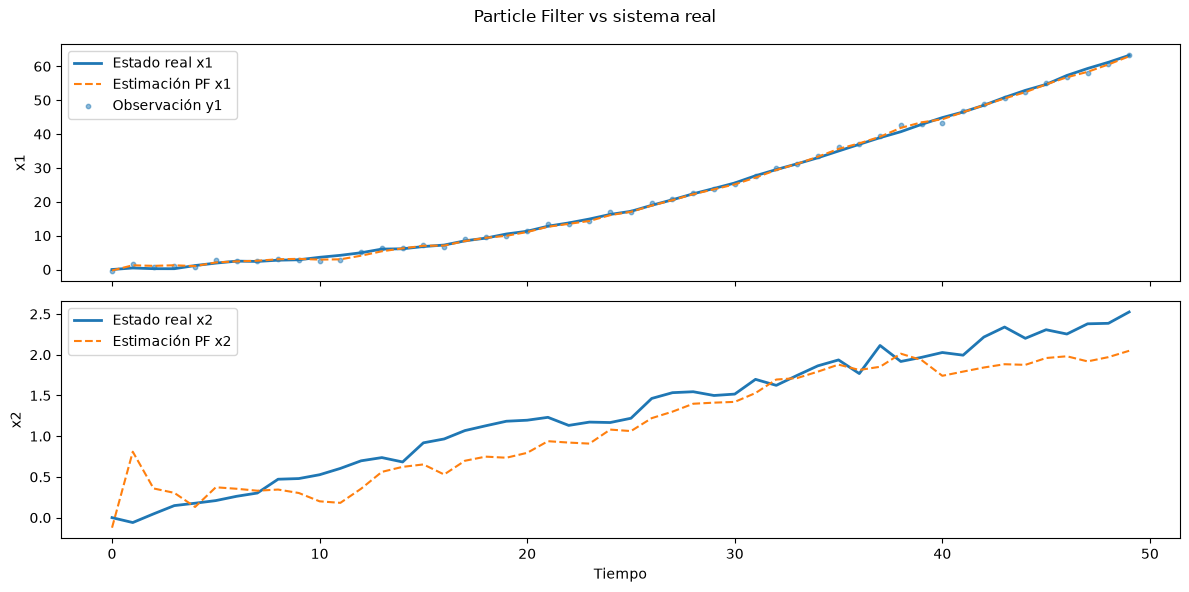

In [12]:
# --- Plot ---
plot_results(x_true, y_obs, x_est)

### EJEMPLO 2D -> OBSERVACION 2D
$$
A = \begin{bmatrix}
1 &1 \\
0 &1
\end{bmatrix}
\;\;
H = \begin{bmatrix}
1 &0 \\
0 &1
\end{bmatrix}
\;\;
Q = \begin{bmatrix}
0.1 &0 \\
0 &0.01
\end{bmatrix}
\;\;
R = \begin{bmatrix}
0.5 &0 \\
0 &0.2
\end{bmatrix}
$$

In [13]:
A = np.array([
    [1., 1.],
    [0., 1.]
])

H = np.eye(2)

Q = np.array([
    [0.1, 0.0],
    [0.0, 0.01]
])

R = np.array([
    [0.5, 0.0],
    [0.0, 0.2]
])

def f(x):
    return A @ x

def h(x):
    return H @ x

In [14]:
#Simulacion
T = 50
x0 = np.array([0.0])

x_true, y_obs = system_simulation(A, H, Q, R, x0, T)

In [15]:
pf = AuxiliaryParticleFilter(
    N=1000,
    state_transition=f,
    measurement_function=h,
    Q=Q,
    R=R
)

pf.initialize(mean=np.array([0.0, 0.0]), cov=np.eye(2))

In [16]:
x_est = pf.run_filter(y_obs, resample_threshold=500)

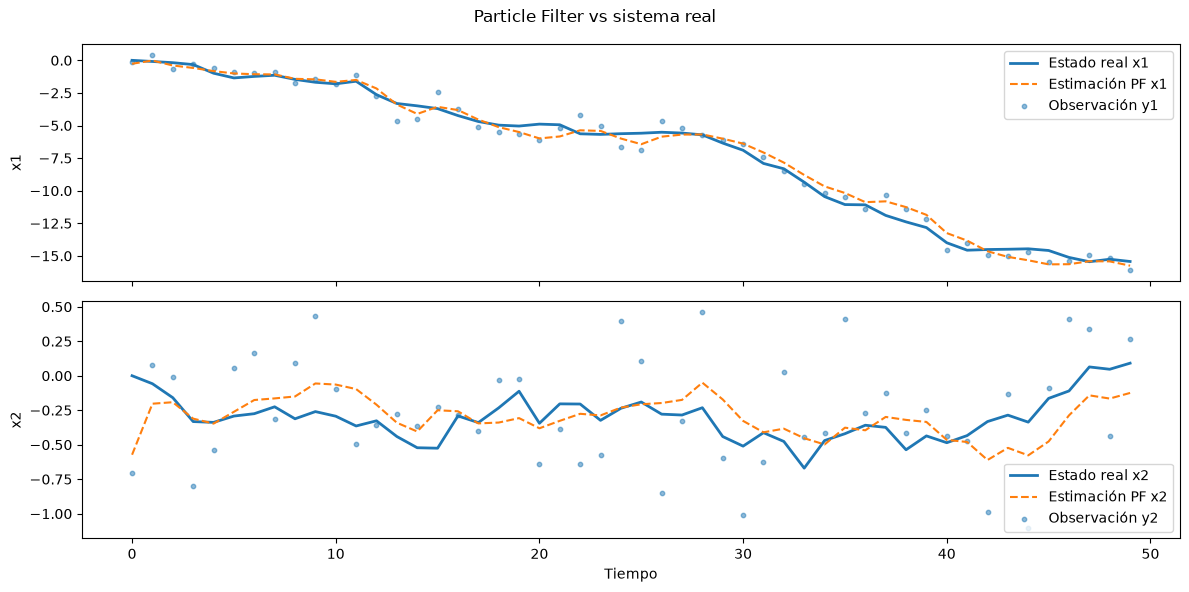

In [17]:
# --- Plot ---
plot_results(x_true, y_obs, x_est)

### EJEMPLO 4D -> OBSERVACION 2D

$$
A = \begin{bmatrix}
1 &0 &1 &0 \\
0 &1 &0 &1\\
0 &0 &1 &0\\
0 &0 &0 &1
\end{bmatrix}
\;\;
H = \begin{bmatrix}
1 &0 &0 &0\\
0 &1 &0 &0
\end{bmatrix}
\;\;
Q = \begin{bmatrix}
0.1 &0 &0 &0\\
0 &0.1 &0 &0\\
0 &0 &0.01 &0\\
0 &0 &0 &0.01
\end{bmatrix}

$$

$$
R = \begin{bmatrix}
0.5 &0 \\
0 &0.5
\end{bmatrix}


$$

In [18]:
A = np.array([
    [1., 0., 1., 0.],
    [0., 1., 0., 1.],
    [0., 0., 1., 0.],
    [0., 0., 0., 1.]
])

H = np.array([
    [1., 0., 0., 0.],
    [0., 1., 0., 0.]
])

Q = np.diag([0.1, 0.1, 0.01, 0.01])

R = np.diag([0.5, 0.5])

In [19]:
#Simulacion
T = 50
x0 = np.array([0.0, 0.0, 0.0, 0.0])

x_true, y_obs = system_simulation(A, H, Q, R, x0, T)

In [20]:
pf = AuxiliaryParticleFilter(
    N=1000,
    state_transition=f,
    measurement_function=h,
    Q=Q,
    R=R
)

pf.initialize(mean=np.array([0.0, 0.0, 0.0, 0.0]), cov=np.eye(4))

In [21]:
x_est = pf.run_filter(y_obs, resample_threshold=500)

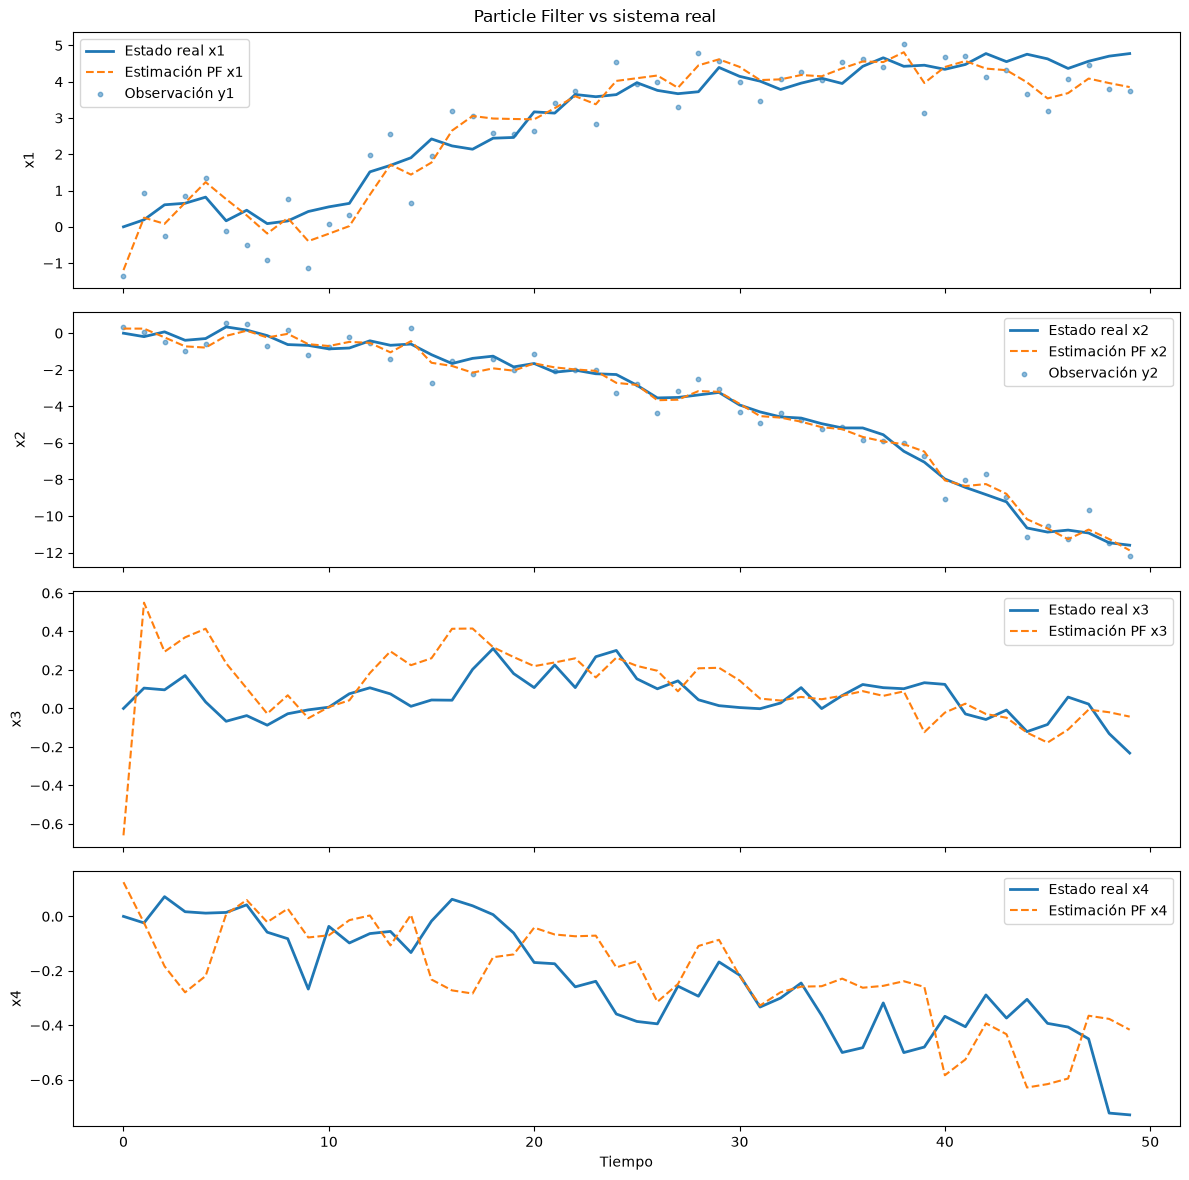

In [22]:
# --- Plot ---
plot_results(x_true, y_obs, x_est)